In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

print("Library berhasil diimpor")


Library berhasil diimpor


In [2]:

from google.colab import files

df = pd.read_csv("Rounded_Student_Hours_Studied_vs_Marks_Dataset.csv")

print("Dataset berhasil dibaca")
display(df.head())


Dataset berhasil dibaca


,Hours_Studied,Marks
0,4.76,46.27
1,3.00,34.30
2,2.08,33.63
3,4.04,47.81
4,9.49,66.26


In [3]:

# Melihat ukuran dataset
print("Jumlah baris dan kolom:", df.shape)

# Melihat informasi dataset
print("\nInformasi Dataset")
df.info()

# Memeriksa data kosong
print("\nData Kosong")
print(df.isnull().sum())

# Statistik deskriptif
print("\nStatistik Deskriptif")
display(df.describe())


Jumlah baris dan kolom: (100, 2)

Informasi Dataset
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Hours_Studied  100 non-null    float64
 1   Marks          100 non-null    float64
dtypes: float64(2)
memory usage: 1.7 KB

Data Kosong
Hours_Studied    0
Marks            0
dtype: int64

Statistik Deskriptif


,Hours_Studied,Marks
count,100.000000,100.000000
mean,5.376300,46.360200
std,2.593013,14.284805
min,1.050000,20.190000
25%,3.175000,33.675000
50%,5.565000,47.485000
75%,7.255000,57.377500
max,9.870000,73.260000


In [4]:

# Mengambil variabel Marks
nilai = df["Marks"].to_numpy()

# Jumlah sampel
n = len(nilai)

print("Jumlah sampel:", n)
print("Data nilai mahasiswa:")
print(nilai)


Jumlah sampel: 100
Data nilai mahasiswa:
[46.27 34.3  33.63 47.81 66.26 38.37 56.24 60.47 39.02 71.44 65.99 34.
 48.59 28.97 29.19 23.85 47.37 49.19 22.78 30.48 73.2  34.65 31.86 39.9
 66.63 36.45 49.49 61.15 32.69 56.31 38.54 62.72 53.44 43.82 33.18 56.48
 40.48 23.59 20.19 52.57 59.18 26.6  47.47 33.69 46.64 29.25 53.79 47.69
 68.87 22.37 41.97 28.18 63.23 67.54 41.76 59.36 57.58 48.44 50.49 40.76
 26.79 64.45 59.99 47.51 44.32 47.5  57.31 70.39 66.73 56.87 55.7  36.48
 32.09 73.26 39.19 29.52 30.   53.36 25.69 22.3  48.59 57.92 61.73 32.5
 53.01 33.17 44.22 60.24 51.58 65.78 55.08 55.42 25.71 39.91 34.97 28.66
 70.27 43.99 65.17 52.23]


In [5]:

# Estimasi titik
rata_rata = np.mean(nilai)

# Standar deviasi sampel
std = np.std(nilai, ddof=1)

# Standard Error
se = std / np.sqrt(n)

# Nilai Z untuk tingkat kepercayaan 95%
z = norm.ppf(0.975)

# Interval kepercayaan
batas_bawah = rata_rata - z * se
batas_atas = rata_rata + z * se

print("HASIL ESTIMASI Z")
print("Jumlah sampel:", n)
print("Rata-rata:", round(rata_rata, 4))
print("Standar deviasi:", round(std, 4))
print("Standard Error:", round(se, 4))
print("Nilai Z:", round(z, 2))
print("Batas bawah:", round(batas_bawah, 4))
print("Batas atas:", round(batas_atas, 4))


HASIL ESTIMASI Z
Jumlah sampel: 100
Rata-rata: 46.3602
Standar deviasi: 14.2848
Standard Error: 1.4285
Nilai Z: 1.96
Batas bawah: 43.5604
Batas atas: 49.16


In [6]:

# Proses Jackknife
jackknife_means = []

for i in range(n):
    data_jackknife = np.delete(nilai, i)

    mean_jackknife = np.mean(data_jackknife)

    jackknife_means.append(mean_jackknife)

# Rata-rata hasil Jackknife
rata_jackknife = np.mean(jackknife_means)

# Standard Error Jackknife
se_jackknife = np.sqrt(
    (n-1)/n * np.sum(
        (np.array(jackknife_means) - rata_jackknife)**2
    )
)

print("HASIL JACKKNIFE")
print("Jumlah resampling:", len(jackknife_means))
print("Rata-rata Jackknife:", round(rata_jackknife, 4))
print("Standard Error:", round(se_jackknife, 4))


HASIL JACKKNIFE
Jumlah resampling: 100
Rata-rata Jackknife: 46.3602
Standard Error: 1.4285


In [7]:

# Mengatur angka acak
rng = np.random.default_rng(42)

# Menyiapkan tempat hasil Bootstrap
bootstrap_means = []

# Proses 1000 iterasi
for i in range(1000):

    data_bootstrap = rng.choice(
        nilai,
        size=n,
        replace=True
    )

    mean_bootstrap = np.mean(data_bootstrap)

    bootstrap_means.append(mean_bootstrap)

# Menghitung rata-rata hasil Bootstrap
rata_bootstrap = np.mean(bootstrap_means)

# Menghitung interval kepercayaan Bootstrap
ci_bootstrap = np.percentile(
    bootstrap_means,
    [2.5, 97.5]
)

print("HASIL BOOTSTRAPPING")
print("Jumlah iterasi:", len(bootstrap_means))
print("Rata-rata Bootstrap:", round(rata_bootstrap, 4))
print("Batas bawah:", round(ci_bootstrap[0], 4))
print("Batas atas:", round(ci_bootstrap[1], 4))


HASIL BOOTSTRAPPING
Jumlah iterasi: 1000
Rata-rata Bootstrap: 46.4105
Batas bawah: 43.5788
Batas atas: 49.3027


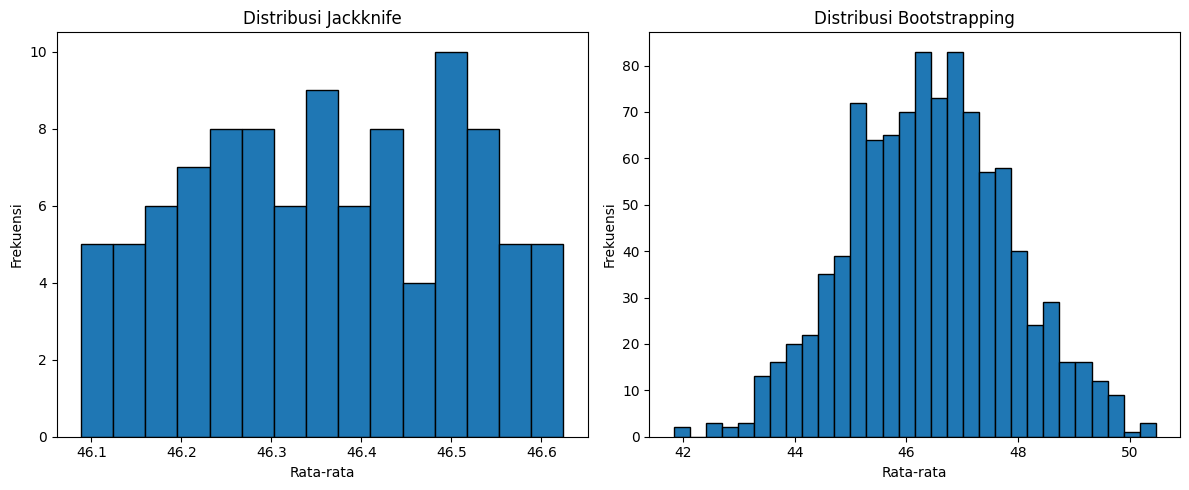

In [8]:

plt.figure(figsize=(12, 5))

# Grafik Jackknife
plt.subplot(1, 2, 1)
plt.hist(jackknife_means, bins=15, edgecolor="black")
plt.title("Distribusi Jackknife")
plt.xlabel("Rata-rata")
plt.ylabel("Frekuensi")

# Grafik Bootstrapping
plt.subplot(1, 2, 2)
plt.hist(bootstrap_means, bins=30, edgecolor="black")
plt.title("Distribusi Bootstrapping")
plt.xlabel("Rata-rata")
plt.ylabel("Frekuensi")

plt.tight_layout()
plt.show()


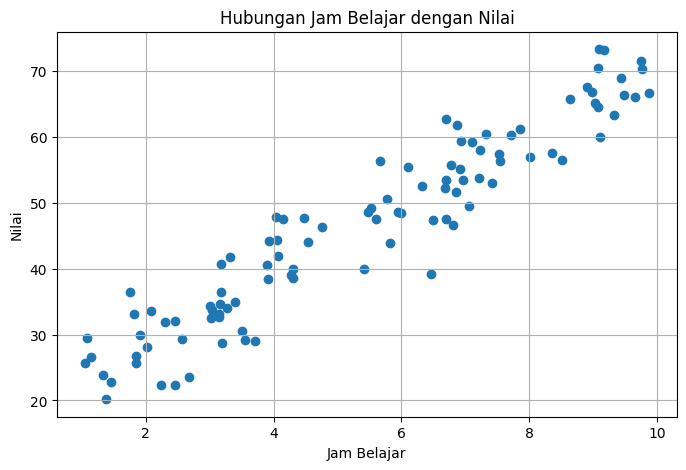

In [9]:

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Hours_Studied"],
    df["Marks"]
)

plt.title("Hubungan Jam Belajar dengan Nilai")
plt.xlabel("Jam Belajar")
plt.ylabel("Nilai")
plt.grid(True)

plt.show()


In [10]:

hasil = pd.DataFrame({
    "Metode": [
        "Estimasi Z",
        "Jackknife",
        "Bootstrapping"
    ],
    "Jumlah Proses": [
        100,
        100,
        1000
    ],
    "Rata-rata": [
        rata_rata,
        rata_jackknife,
        rata_bootstrap
    ]
})

display(hasil.round(4))


,Metode,Jumlah Proses,Rata-rata
0,Estimasi Z,100,46.3602
1,Jackknife,100,46.3602
2,Bootstrapping,1000,46.4105
